###**Loading and Extracting the Data**

In [ ]:
import os
import subprocess

rar_path = '/content/NEU-CLS.rar'
extract_path = '/content/NEU-CLS'

os.makedirs(extract_path, exist_ok=True)

try:
    subprocess.run(['unrar', 'x', rar_path, extract_path], check=True)
    print(f"Successfully extracted {rar_path} to {extract_path}")

except subprocess.CalledProcessError as e:
    print(f"An error occurred during extraction: {e}")

Successfully extracted /content/NEU-CLS.rar to /content/NEU-CLS


### **Overviewing the Data and Assigning the Classes**

In [ ]:
import os
import shutil
from collections import defaultdict

source_dir = '/content/NEU-CLS/NEU-CLS'
output_dir = '/content/NEU-CLS_Structured'

class_mapping = {
    'Cr_': 'Crazing',
    'In_': 'Inclusion',
    'Pa_': 'Patches',
    'PS_': 'Pitted_Surface',
    'RS_': 'Rolled-in_Scale',
    'Sc_': 'Scratches'
}


os.makedirs(output_dir, exist_ok=True)
for class_name in class_mapping.values():
    os.makedirs(os.path.join(output_dir, class_name), exist_ok=True)

stats = defaultdict(int)
unknown_count = 0

print("Organizing files into class folders...")
for filename in os.listdir(source_dir):
    source_file_path = os.path.join(source_dir, filename)


    if os.path.isdir(source_file_path) or filename.startswith('.'):
        continue

    matched = False
    for prefix, class_folder in class_mapping.items():
        if filename.startswith(prefix):
            dest_path = os.path.join(output_dir, class_folder, filename)
            shutil.copy2(source_file_path, dest_path) # Using copy2 to preserve metadata. Change to shutil.move if you want to save space.
            stats[class_folder] += 1
            matched = True
            break

    if not matched:
        unknown_count += 1

print("\n--- Summary ---")
for class_folder, count in stats.items():
    print(f"Class '{class_folder}': {count} files mapped.")
if unknown_count > 0:
    print(f"Unmapped/ignored files: {unknown_count}")

Organizing files into class folders...

--- Summary ---
Class 'Inclusion': 300 files mapped.
Class 'Pitted_Surface': 300 files mapped.
Class 'Rolled-in_Scale': 300 files mapped.
Class 'Patches': 300 files mapped.
Class 'Scratches': 300 files mapped.
Class 'Crazing': 300 files mapped.
Unmapped/ignored files: 1


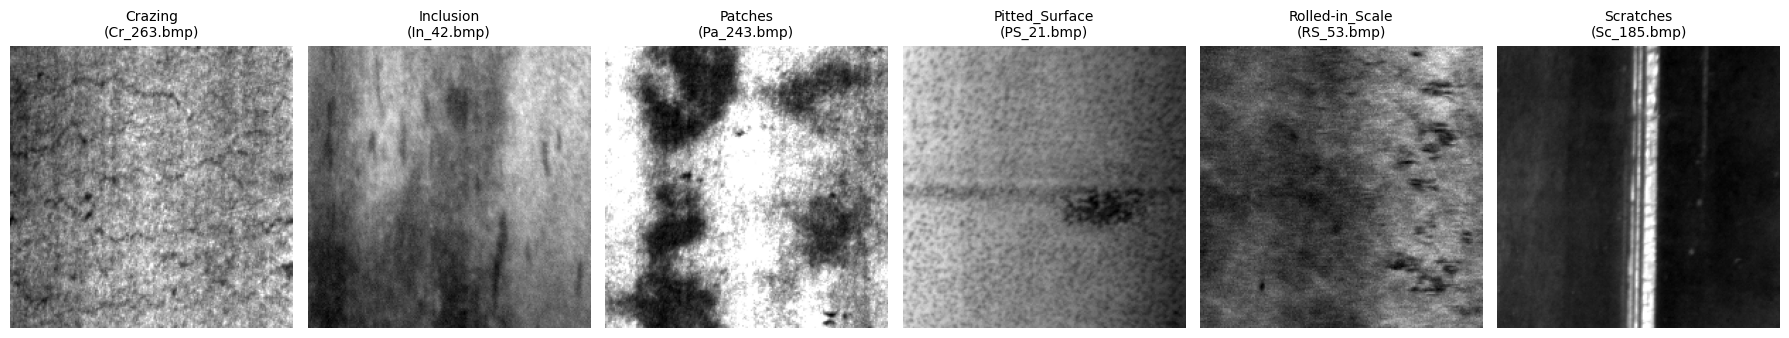

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

structured_dir = '/content/NEU-CLS_Structured'

classes = sorted([d for d in os.listdir(structured_dir) if os.path.isdir(os.path.join(structured_dir, d))])


fig, axes = plt.subplots(1, len(classes), figsize=(18, 5))

for i, class_name in enumerate(classes):
    class_path = os.path.join(structured_dir, class_name)
    files = [f for f in os.listdir(class_path) if f.endswith(('.bmp', '.png', '.jpg', '.jpeg'))]

    if files:
        random_file = random.choice(files)
        image_path = os.path.join(class_path, random_file)

        img = Image.open(image_path)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"{class_name}\n({random_file})", fontsize=10)
        axes[i].axis('off')
    else:
        axes[i].text(0.5, 0.5, 'No Image Found', ha='center', va='center')
        axes[i].set_title(class_name)
        axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
from PIL import Image

classes = sorted([d for d in os.listdir(structured_dir) if os.path.isdir(os.path.join(structured_dir, d))])

metadata_list = []

for class_name in classes:
    class_path = os.path.join(structured_dir, class_name)
    files = [f for f in os.listdir(class_path) if f.endswith(('.bmp', '.png', '.jpg', '.jpeg'))]

    if files:
        sample_file = files[0]
        image_path = os.path.join(class_path, sample_file)

        with Image.open(image_path) as img:
            metadata_list.append({
                'Class': class_name,
                'Sample File': sample_file,
                'Format': img.format,
                'Mode': img.mode,
                'Width (px)': img.size[0],
                'Height (px)': img.size[1],
                'Info Dict Keys': list(img.info.keys())
            })

metadata_df = pd.DataFrame(metadata_list)
display(metadata_df)

,Class,Sample File,Format,Mode,Width (px),Height (px),Info Dict Keys
0,Crazing,Cr_22.bmp,BMP,L,200,200,"[dpi, compression]"
1,Inclusion,In_160.bmp,BMP,L,200,200,"[dpi, compression]"
2,Patches,Pa_214.bmp,BMP,L,200,200,"[dpi, compression]"
3,Pitted_Surface,PS_197.bmp,BMP,L,200,200,"[dpi, compression]"
4,Rolled-in_Scale,RS_149.bmp,BMP,L,200,200,"[dpi, compression]"
5,Scratches,Sc_63.bmp,BMP,L,200,200,"[dpi, compression]"


### **Initializing the Data Split**

In [ ]:
from tensorflow import keras

In [ ]:
import tensorflow as tf
from tensorflow import keras

SEED = 7
BATCH_SIZE = 64
IMAGE_SIZE = (200, 200)


temp_train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/NEU-CLS_Structured',
    labels='inferred',
    label_mode='int',
    validation_split=0.1,
    subset='training',
    seed=SEED,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

test_ds = keras.utils.image_dataset_from_directory(
    directory='/content/NEU-CLS_Structured',
    labels='inferred',
    label_mode='int',
    validation_split=0.1,
    subset='validation',
    seed=SEED,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

total_batches = len(temp_train_ds)
train_batches = int(total_batches * (7 / 9))

train_ds = temp_train_ds.take(train_batches)
validation_ds = temp_train_ds.skip(train_batches)

print(f"Total batches in temp dataset: {total_batches}")
print(f"Batches allocated to Train: {len(train_ds)}")
print(f"Batches allocated to Validation: {len(validation_ds)}")
print(f"Batches allocated to Test: {len(test_ds)}")

Found 1800 files belonging to 6 classes.
Using 1620 files for training.
Found 1800 files belonging to 6 classes.
Using 180 files for validation.
Total batches in temp dataset: 26
Batches allocated to Train: 20
Batches allocated to Validation: 6
Batches allocated to Test: 3


### **Data Augmentation Pipeline**

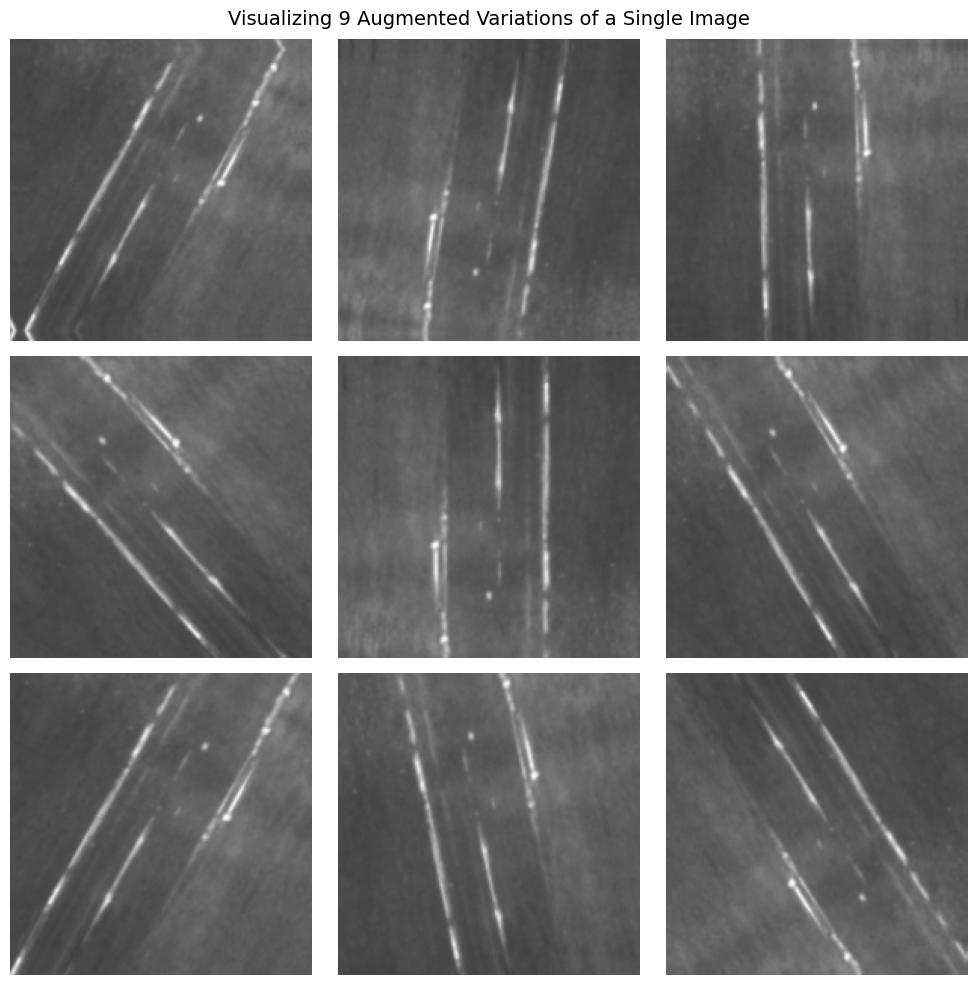

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt


data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])


for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    first_image = images[0]

    for i in range(9):

        augmented_image = data_augmentation(tf.expand_dims(first_image, 0), training=True)

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_image[0].numpy().astype("uint8"), cmap='gray')
        plt.axis("off")

    plt.suptitle("Visualizing 9 Augmented Variations of a Single Image", fontsize=14)
    plt.tight_layout()
    plt.show()

In [ ]:
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

def augment(images, labels):
    return data_augmentation(images, training=True), labels

augmented_train_ds = train_ds.map(augment, num_parallel_calls=AUTOTUNE)


optimized_train_ds = augmented_train_ds.cache().prefetch(buffer_size=AUTOTUNE)
optimized_val_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Optimized dataset pipelines are ready.")

Optimized dataset pipelines are ready.


### **Creating a Baseline CNN Model - E0**

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers


model_E0 = keras.Sequential([

    layers.Rescaling(1./255, input_shape=(200, 200, 3)),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(6, activation='softmax')
])

model_E0.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_E0.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 200, 200, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,678 (127.65 KB)

 Trainable params: 32,678 (127.65 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_E0 = model_E0.fit(train_ds, epochs=100, validation_data=validation_ds)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 590ms/step - accuracy: 0.1719 - loss: 1.7779 - val_accuracy: 0.1971 - val_loss: 1.7455
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.2109 - loss: 1.7473 - val_accuracy: 0.2441 - val_loss: 1.7178
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.3172 - loss: 1.6508 - val_accuracy: 0.3853 - val_loss: 1.5243
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.4320 - loss: 1.3812 - val_accuracy: 0.5471 - val_loss: 1.1713
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.6078 - loss: 1.0642 - val_accuracy: 0.7176 - val_loss: 0.8848
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - accuracy: 0.5820 - loss: 0.9948 - val_accuracy: 0.5882 - val_loss: 0.8660
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.7664 - loss: 0.7576 - val_accuracy: 0.7971 - val_loss: 0.6751
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.7711 - loss: 0.6435 - val_accuracy:

Evaluating model_E4 on the test dataset...
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.9833 - loss: 0.0546
Test Accuracy: 98.33%
Test Loss: 0.0546
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


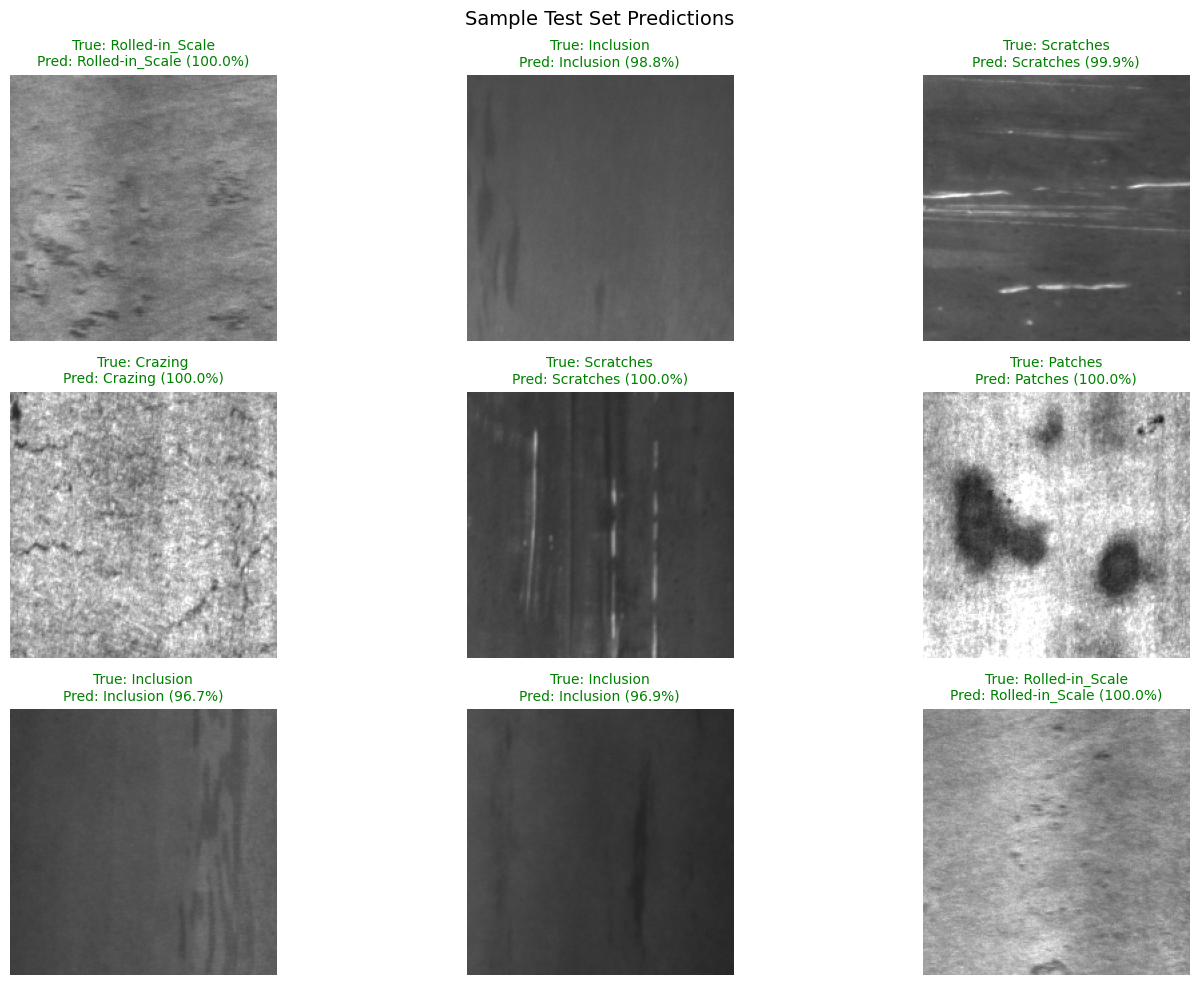

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Evaluating model_E4 on the test dataset...")
test_loss, test_acc = model_E0.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

class_names = test_ds.class_names

for images, labels in test_ds.take(1):
    predictions = model_E0.predict(images)

    plt.figure(figsize=(15, 10))
    for i in range(min(9, len(images))):
        predicted_label_index = np.argmax(predictions[i])
        true_label_index = labels[i].numpy()

        predicted_name = class_names[predicted_label_index]
        true_name = class_names[true_label_index]
        confidence = predictions[i][predicted_label_index] * 100

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"), cmap='gray')

        color = "green" if predicted_label_index == true_label_index else "red"
        plt.title(f"True: {true_name}\nPred: {predicted_name} ({confidence:.1f}%)", color=color, fontsize=10)
        plt.axis("off")

    plt.suptitle("Sample Test Set Predictions", fontsize=14)
    plt.tight_layout()
    plt.show()

### **Introducing Callbacks and LR Scheduling - E1**

In [ ]:
model_E1 = keras.Sequential([

    layers.Rescaling(1./255, input_shape=(200, 200, 3)),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(6, activation='softmax')
])

model_E1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=50,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=25,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        'best_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    )
]

In [ ]:
history_E1 = model_E1.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 143ms/step - accuracy: 0.1609 - loss: 1.7757 - val_accuracy: 0.1500 - val_loss: 1.7588 - learning_rate: 0.0010
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.1813 - loss: 1.7550 - val_accuracy: 0.2765 - val_loss: 1.7304 - learning_rate: 0.0010
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.2539 - loss: 1.7059 - val_accuracy: 0.4000 - val_loss: 1.6428 - learning_rate: 0.0010
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.3578 - loss: 1.5663 - val_accuracy: 0.5000 - val_loss: 1.4238 - learning_rate: 0.0010
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.4898 - loss: 1.2895 - val_accuracy: 0.5941 - val_loss: 1.1134 - learning_rate: 0.0010
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.5883 - loss: 1.0587 - val_accuracy: 0.6912 - val_loss: 0.9111 - learning_rate: 0.0010
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.6555 - loss: 0.8851 -

Evaluating model_E1 on the test dataset...
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 399ms/step - accuracy: 0.9833 - loss: 0.0792
Test Accuracy: 98.33%
Test Loss: 0.0792
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step 


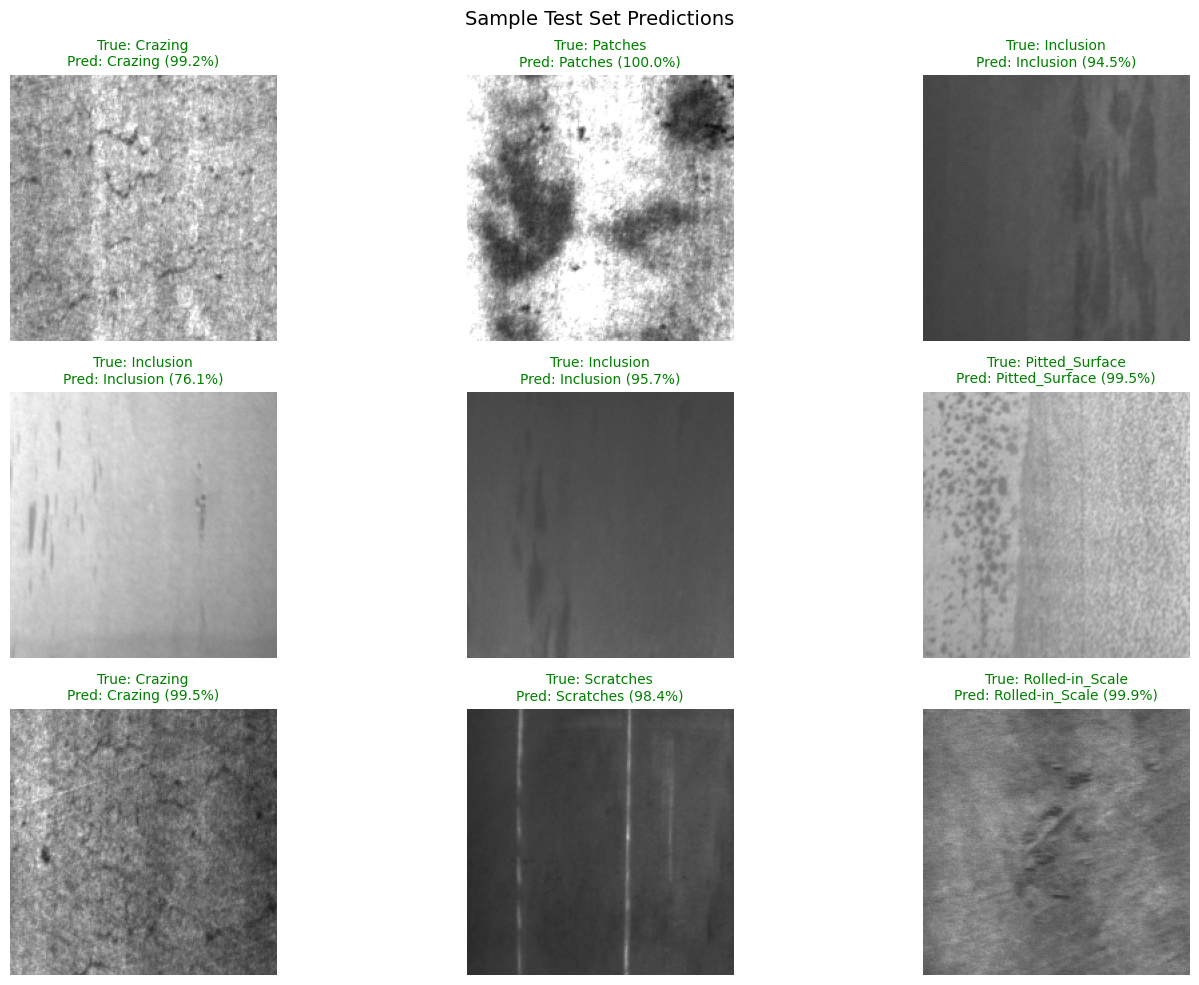

In [ ]:
print("Evaluating model_E1 on the test dataset...")
test_loss, test_acc = model_E1.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

class_names = test_ds.class_names

for images, labels in test_ds.take(1):
    predictions = model_E1.predict(images)

    plt.figure(figsize=(15, 10))
    for i in range(min(9, len(images))):
        predicted_label_index = np.argmax(predictions[i])
        true_label_index = labels[i].numpy()

        predicted_name = class_names[predicted_label_index]
        true_name = class_names[true_label_index]
        confidence = predictions[i][predicted_label_index] * 100

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"), cmap='gray')

        color = "green" if predicted_label_index == true_label_index else "red"
        plt.title(f"True: {true_name}\nPred: {predicted_name} ({confidence:.1f}%)", color=color, fontsize=10)
        plt.axis("off")

    plt.suptitle("Sample Test Set Predictions", fontsize=14)
    plt.tight_layout()
    plt.show()

### **Increasing the Filter Capacity - E2**

In [ ]:
model_E2 = keras.Sequential([

    layers.Rescaling(1./255, input_shape=(200, 200, 3)),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(6, activation='softmax')
])

model_E2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
history_E2 = model_E2.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 174ms/step - accuracy: 0.1570 - loss: 1.7822 - val_accuracy: 0.2000 - val_loss: 1.7537 - learning_rate: 0.0010
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.2492 - loss: 1.7202 - val_accuracy: 0.2294 - val_loss: 1.6752 - learning_rate: 0.0010
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.3258 - loss: 1.4784 - val_accuracy: 0.3853 - val_loss: 1.3095 - learning_rate: 0.0010
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.5016 - loss: 1.1958 - val_accuracy: 0.6559 - val_loss: 1.0108 - learning_rate: 0.0010
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 155ms/step - accuracy: 0.6273 - loss: 0.9291 - val_accuracy: 0.7971 - val_loss: 0.7051 - learning_rate: 0.0010
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step - accuracy: 0.7031 - loss: 0.7384 - val_accuracy: 0.7118 - val_loss: 0.6877 - learning_rate: 0.0010
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.7328 - loss: 0.

Evaluating model_E2 on the test dataset...
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.9722 - loss: 0.0657
Test Accuracy: 97.22%
Test Loss: 0.0657
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step


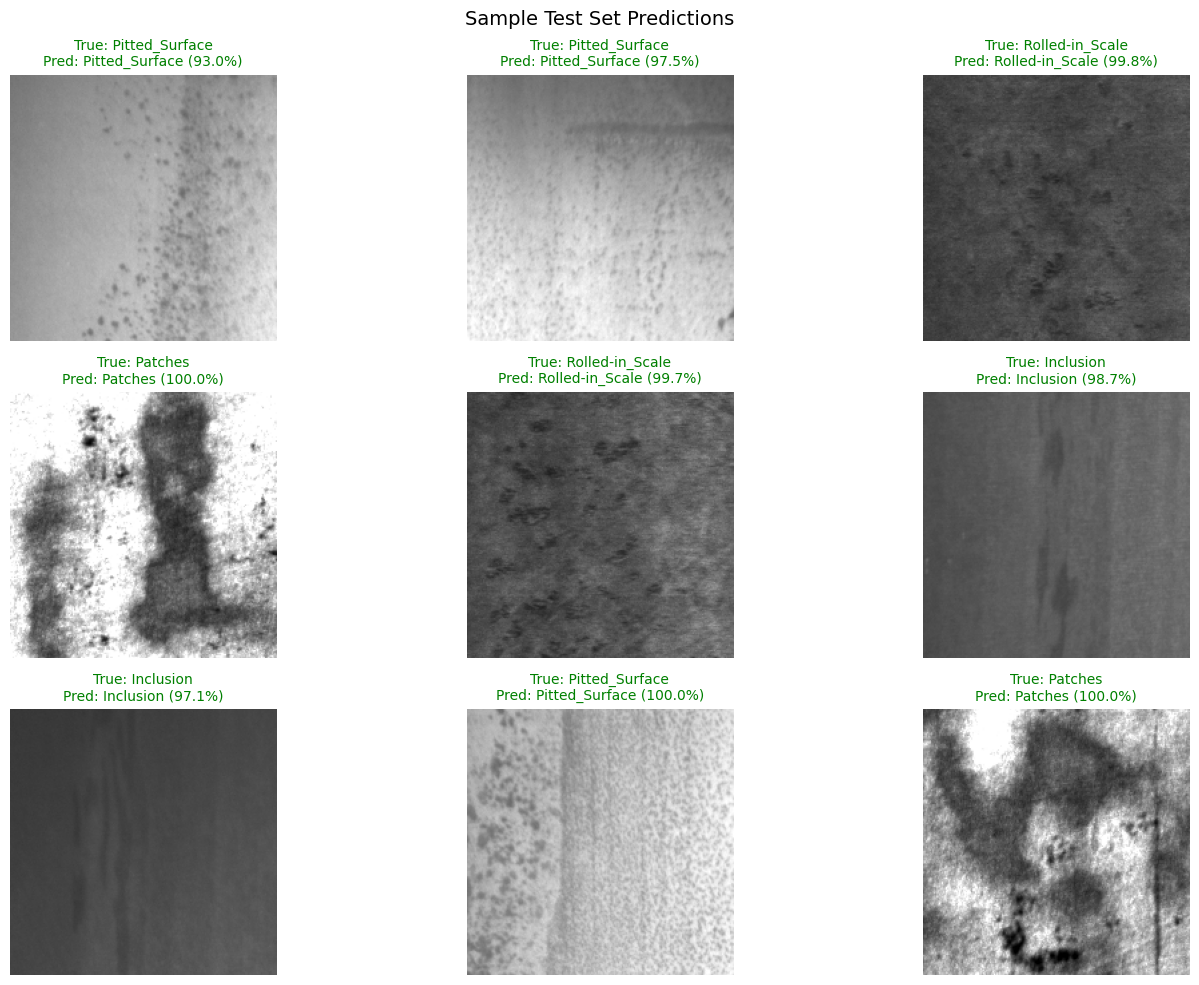

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Evaluating model_E2 on the test dataset...")
test_loss, test_acc = model_E2.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

class_names = test_ds.class_names

for images, labels in test_ds.take(1):
    predictions = model_E2.predict(images)

    plt.figure(figsize=(15, 10))
    for i in range(min(9, len(images))):
        predicted_label_index = np.argmax(predictions[i])
        true_label_index = labels[i].numpy()

        predicted_name = class_names[predicted_label_index]
        true_name = class_names[true_label_index]
        confidence = predictions[i][predicted_label_index] * 100

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"), cmap='gray')

        color = "green" if predicted_label_index == true_label_index else "red"
        plt.title(f"True: {true_name}\nPred: {predicted_name} ({confidence:.1f}%)", color=color, fontsize=10)
        plt.axis("off")

    plt.suptitle("Sample Test Set Predictions", fontsize=14)
    plt.tight_layout()
    plt.show()

### **Introducing Batch Normalization - E3**

In [ ]:
model_E3 = keras.Sequential([

    layers.Rescaling(1./255, input_shape=(200, 200, 3)),

    layers.Conv2D(32, 3, padding='same', use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding='same', use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(),


    layers.GlobalAveragePooling2D(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),

    layers.Dense(64, use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),

    layers.Dense(6, activation='softmax')
])

model_E3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
history_E3 = model_E3.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 248ms/step - accuracy: 0.6586 - loss: 0.9697 - val_accuracy: 0.2235 - val_loss: 2.2862 - learning_rate: 0.0010
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.8555 - loss: 0.5284 - val_accuracy: 0.3059 - val_loss: 2.6229 - learning_rate: 0.0010
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.8719 - loss: 0.4284 - val_accuracy: 0.7235 - val_loss: 0.7495 - learning_rate: 0.0010
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - accuracy: 0.8758 - loss: 0.3708 - val_accuracy: 0.8382 - val_loss: 0.4934 - learning_rate: 0.0010
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.9023 - loss: 0.3096 - val_accuracy: 0.8235 - val_loss: 0.5336 - learning_rate: 0.0010
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - accuracy: 0.9008 - loss: 0.2910 - val_accuracy: 0.9029 - val_loss: 0.3797 - learning_rate: 0.0010
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 132ms/step - accuracy: 0.9211 - loss: 0

Evaluating model_E3 on the test dataset...
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.9944 - loss: 0.0110
Test Accuracy: 99.44%
Test Loss: 0.0110
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step


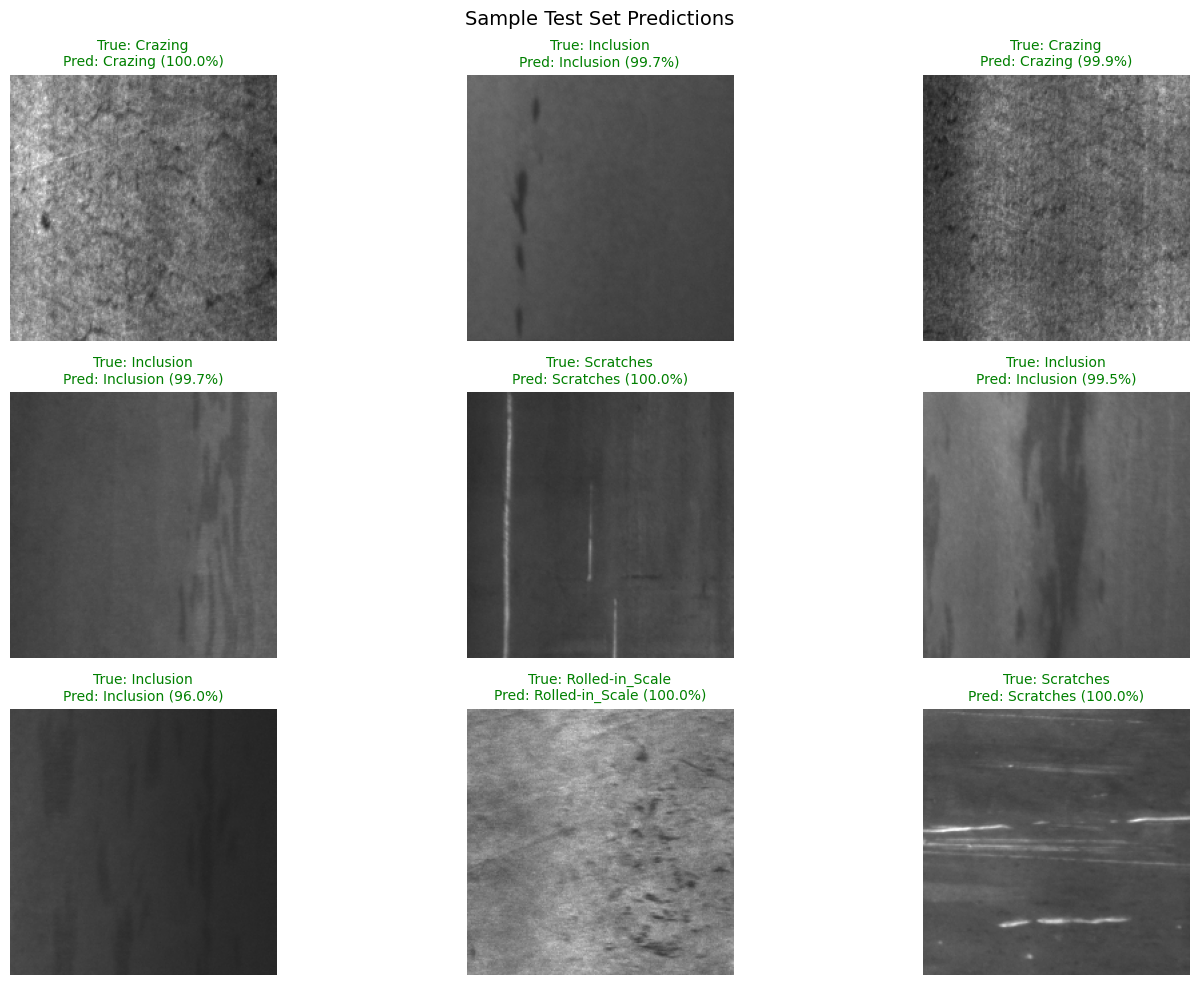

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Evaluating model_E3 on the test dataset...")
test_loss, test_acc = model_E3.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

class_names = test_ds.class_names

for images, labels in test_ds.take(1):
    predictions = model_E3.predict(images)

    plt.figure(figsize=(15, 10))
    for i in range(min(9, len(images))):
        predicted_label_index = np.argmax(predictions[i])
        true_label_index = labels[i].numpy()

        predicted_name = class_names[predicted_label_index]
        true_name = class_names[true_label_index]
        confidence = predictions[i][predicted_label_index] * 100

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"), cmap='gray')

        color = "green" if predicted_label_index == true_label_index else "red"
        plt.title(f"True: {true_name}\nPred: {predicted_name} ({confidence:.1f}%)", color=color, fontsize=10)
        plt.axis("off")

    plt.suptitle("Sample Test Set Predictions", fontsize=14)
    plt.tight_layout()
    plt.show()

### **Saving the Models**

In [ ]:
model_E0.save('model_E0.keras')
model_E1.save('model_E1.keras')
model_E2.save('model_E2.keras')
model_E3.save('model_E3.keras')

print("Successfully saved all models:")
print("- model_E0.keras")
print("- model_E1.keras")
print("- model_E2.keras")
print("- model_E3.keras")

Successfully saved all models:
- model_E0.keras
- model_E1.keras
- model_E2.keras
- model_E3.keras


### **Analyzing the Errors on Best Model (E3)**


Test Loss: 0.0110
Test Accuracy: 99.44%
                 precision    recall  f1-score   support

        Crazing       1.00      1.00      1.00        32
      Inclusion       0.97      1.00      0.99        36
        Patches       1.00      1.00      1.00        24
 Pitted_Surface       1.00      1.00      1.00        34
Rolled-in_Scale       1.00      1.00      1.00        30
      Scratches       1.00      0.96      0.98        24

       accuracy                           0.99       180
      macro avg       1.00      0.99      0.99       180
   weighted avg       0.99      0.99      0.99       180



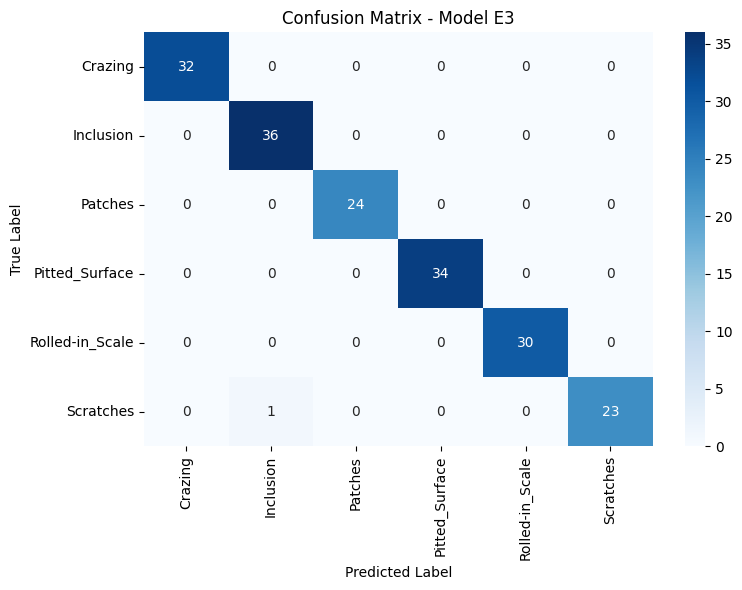


Total misclassified test samples: 1 out of 180


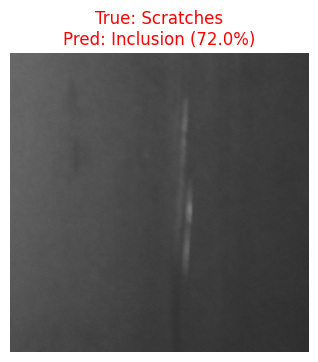

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


test_loss, test_acc = model_E3.evaluate(test_ds, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")


all_images = []
all_labels = []
all_preds = []
all_probs = []

class_names = test_ds.class_names

for images, labels in test_ds:
    preds = model_E3.predict(images, verbose=0)
    all_images.append(images.numpy())
    all_labels.append(labels.numpy())
    all_preds.append(np.argmax(preds, axis=1))
    all_probs.append(preds)

all_images = np.concatenate(all_images, axis=0)
all_labels = np.concatenate(all_labels, axis=0)
all_preds = np.concatenate(all_preds, axis=0)
all_probs = np.concatenate(all_probs, axis=0)

print(classification_report(all_labels, all_preds, target_names=class_names))


cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Model E3')
plt.tight_layout()
plt.show()


misclassified_indices = np.where(all_preds != all_labels)[0]
print(f"\nTotal misclassified test samples: {len(misclassified_indices)} out of {len(all_labels)}")

if len(misclassified_indices) > 0:
    plt.figure(figsize=(15, 10))
    num_to_show = min(9, len(misclassified_indices))
    for idx, mis_idx in enumerate(misclassified_indices[:num_to_show]):
        true_idx = all_labels[mis_idx]
        pred_idx = all_preds[mis_idx]
        confidence = all_probs[mis_idx][pred_idx] * 100

        ax = plt.subplot(3, 3, idx + 1)
        plt.imshow(all_images[mis_idx].astype("uint8"), cmap='gray')
        plt.title(f"True: {class_names[true_idx]}\nPred: {class_names[pred_idx]} ({confidence:.1f}%)", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Excellent! No misclassified samples found in the test dataset.")

### **Inference Preparation**

In [ ]:
for index, name in enumerate(class_names):
    print(f"Index {index} -> {name}")

Index 0 -> Crazing
Index 1 -> Inclusion
Index 2 -> Patches
Index 3 -> Pitted_Surface
Index 4 -> Rolled-in_Scale
Index 5 -> Scratches


In [ ]:
model_E3.summary()

print("Input shape:", model_E3.input_shape)
print("Output shape:", model_E3.output_shape)
print("Classes:", class_names)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 200, 200, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 200, 200, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 200, 200, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 100, 100, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 50, 50, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,300 (1.36 MB)

 Trainable params: 118,822 (464.15 KB)

 Non-trainable params: 832 (3.25 KB)

 Optimizer params: 237,646 (928.31 KB)

Input shape: (None, 200, 200, 3)
Output shape: (None, 6)
Classes: ['Crazing', 'Inclusion', 'Patches', 'Pitted_Surface', 'Rolled-in_Scale', 'Scratches']


In [ ]:

import json
import numpy as np
import tensorflow as tf

from pathlib import Path
from PIL import Image


MODEL_PATH = "/content/model_E3.keras"
CLASSES_PATH = "/content/class_names.json"


class DefectClassifier:

    def __init__(self):
        self.model = tf.keras.models.load_model(MODEL_PATH)

        with open(CLASSES_PATH, "r") as f:
            self.class_names = json.load(f)

    def preprocess_image(self, image: Image.Image):

        image = image.convert("RGB")
        image = image.resize((200, 200))

        image_array = np.asarray(image, dtype=np.float32)

        image_array = np.expand_dims(image_array, axis=0)

        return image_array

    def predict(self, image: Image.Image):

        processed_image = self.preprocess_image(image)

        predictions = self.model.predict(
            processed_image,
            verbose=0
        )

        predicted_index = int(np.argmax(predictions[0]))

        confidence = float(predictions[0][predicted_index])

        return {
            "predicted_class": self.class_names[predicted_index],
            "confidence": confidence,
            "probabilities": {
                class_name: float(probability)
                for class_name, probability
                in zip(self.class_names, predictions[0])
            }
        }


In [ ]:
from PIL import Image

classifier = DefectClassifier()

image = Image.open("PS_58.bmp")

result = classifier.predict(image)

print(result)

{'predicted_class': 'Pitted_Surface', 'confidence': 0.8989654779434204, 'probabilities': {'Crazing': 0.00022711993369739503, 'Inclusion': 0.09663622826337814, 'Patches': 0.0005396691267378628, 'Pitted_Surface': 0.8989654779434204, 'Rolled-in_Scale': 0.0027555562555789948, 'Scratches': 0.000875934842042625}}


In [ ]:
from PIL import Image

classifier = DefectClassifier()

image = Image.open("Sc_81.bmp")

result = classifier.predict(image)

print(result)

{'predicted_class': 'Scratches', 'confidence': 0.9998111128807068, 'probabilities': {'Crazing': 5.507089554157574e-06, 'Inclusion': 5.0380825996398926e-05, 'Patches': 7.438642205670476e-05, 'Pitted_Surface': 2.0620245777536184e-05, 'Rolled-in_Scale': 3.796555756707676e-05, 'Scratches': 0.9998111128807068}}


In [ ]:
from PIL import Image

classifier = DefectClassifier()

image = Image.open("RS_195.bmp")

result = classifier.predict(image)

print(result)

{'predicted_class': 'Rolled-in_Scale', 'confidence': 0.9999115467071533, 'probabilities': {'Crazing': 9.415836643711373e-07, 'Inclusion': 2.5497021852061152e-05, 'Patches': 3.379004920134321e-05, 'Pitted_Surface': 5.24742347352003e-07, 'Rolled-in_Scale': 0.9999115467071533, 'Scratches': 2.7638299798127264e-05}}
